# 📊 Project EDA Implementation Guide

---

# 👤 Section 1: Arthunya & Aswin (Standardized EDA Sequence)

## 🔹 Step 1. Shape Check
* **What to Do:** Check number of rows/columns and data type of each column (`df.shape`, `df.dtypes`)
* **Required Output:** One-line summary: "X rows, Y columns"

## 🔹 Step 2. Missing Value Check
* **What to Do:** Check what percentage of each column is missing (`df.isnull().sum()`)
* **Required Output:** Short table/list of columns with missing values (or state there are none)

## 🔹 Step 3. Target Variable Distribution
* **What to Do:** Check class balance of the target variable (`value_counts(normalize=True)`)
* **Required Output:** Clear percentage for each class

## 🔹 Step 4. Descriptive Statistics
* **What to Do:** Run `df.describe()` to check min/max/mean/std for each feature
* **Required Output:** Note any values that look abnormal (e.g., negative minimums, unusually high maximums)

## 🔹 Step 5. Univariate — Histograms
* **What to Do:** Histograms for 5–6 key features
* **Required Output:** Chart(s) + Figure number + caption

## 🔹 Step 6. Bivariate — Correlation Matrix
* **What to Do:** Correlation between every feature and the target
* **Required Output:** Heatmap or sorted correlation table + Figure number

## 🔹 Step 7. Outlier/Anomaly Check
* **What to Do:** Identify abnormal values found in Steps 4–6 (boxplot or manual threshold)
* **Required Output:** List of features with outliers, with example values

## 🔹 Step 8. Written Summary
* **What to Do:** 3–5 sentence summary referencing the actual numbers from Steps 1–7
* **Required Output:** Closing paragraph for the section

---

In [ ]:
## Aswin — Operations Layer

In [ ]:
import kagglehub
import os
import pandas as pd

# Download the latest version of the DataCo dataset
path = kagglehub.dataset_download(
    "shashwatwork/dataco-smart-supply-chain-for-big-data-analysis"
)

print("Path to dataset files:", path)
print("Files:", os.listdir(path))

Using Colab cache for faster access to the 'dataco-smart-supply-chain-for-big-data-analysis' dataset.
Path to dataset files: /kaggle/input/dataco-smart-supply-chain-for-big-data-analysis
Files: ['tokenized_access_logs.csv', 'DataCoSupplyChainDataset.csv', 'DescriptionDataCoSupplyChain.csv']


In [ ]:
data_file = os.path.join(
    path,
    "DataCoSupplyChainDataset.csv"
)

dataco_df = pd.read_csv(
    data_file,
    encoding="latin1"
)

print("Shape:", dataco_df.shape)
dataco_df.head()

Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 🔹 Step 1. Shape Check

In [ ]:
print(f"Shape: {dataco_df.shape[0]} rows, {dataco_df.shape[1]} columns")
display(dataco_df.dtypes)

Shape: 180519 rows, 53 columns


,0
Type,object
Days for shipping (real),int64
Days for shipment (scheduled),int64
Benefit per order,float64
Sales per customer,float64
Delivery Status,object
Late_delivery_risk,int64
Category Id,int64
Category Name,object
Customer City,object


### 🔹 Step 1b. Drop Irrelevant Columns
Removing sensitive information (names, emails) and non-analytical identifiers to streamline the dataset.

In [ ]:
# drop identifiers, personal data, etc.

columns_to_drop = [
    'Customer Fname',
    'Customer Lname',
    'Customer Email',
    'Customer Password',
    'Customer Street',
    'Product Image',
    'Product Description',
    'Category Id',
    'Customer Id',
    'Department Id',
    'Order Customer Id',
    'Order Id',
    'Order Item Cardprod Id',
    'Order Item Id',
    'Product Card Id',
    'Product Category Id'
]

existing_drop_cols = [c for c in columns_to_drop if c in dataco_df.columns]
dataco_df = dataco_df.drop(columns=existing_drop_cols)

print(f"Dropped {len(existing_drop_cols)} columns.")
print(f"New Shape: {dataco_df.shape[0]} rows, {dataco_df.shape[1]} columns")
display(dataco_df.head())


Dropped 7 columns.
New Shape: 180519 rows, 37 columns


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,...,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,-249.089996,South Asia,Rajastán,PENDING,NaN,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,-247.779999,South Asia,Rajastán,CLOSED,NaN,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,22.860001,Oceania,Queensland,COMPLETE,NaN,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 🔹 Step 2. Missing Value Check

In [ ]:
missing_values = dataco_df.isnull().sum()
missing_percentage = (missing_values / len(dataco_df)) * 100
missing_info = pd.DataFrame({"Missing Count": missing_values, "Missing Percentage": missing_percentage})

missing_info = missing_info[missing_info["Missing Count"] > 0].sort_values(by="Missing Percentage", ascending=False)

if not missing_info.empty:
    print("Columns with missing values:")
    display(missing_info)
else:
    print("No missing values in the DataFrame.")

Columns with missing values:


,Missing Count,Missing Percentage
Order Zipcode,155679,86.239676
Customer Zipcode,3,0.001662


## 🔹 Step 3. Target Variable Distribution

In [ ]:
target_variable = 'Late_delivery_risk'

if target_variable in dataco_df.columns:
    print(f"Distribution of '{target_variable}':")
    target_counts = dataco_df[target_variable].value_counts(normalize=True) * 100
    display(target_counts.to_frame(name='Percentage'))
else:
    print(f"Target variable '{target_variable}' not found in DataFrame.")

Distribution of 'Late_delivery_risk':


,Percentage
Late_delivery_risk,
1,54.829132
0,45.170868


## 🔹 Step 4. Descriptive Statistics

In [ ]:
description = dataco_df.describe()
display(description)

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Customer Zipcode,Latitude,Longitude,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,35921.126914,29.719955,-84.915675,20.664741,0.101668,141.232550,0.120647,2.127638,203.772096,183.107609,21.974989,55426.132327,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,37542.461122,9.813646,21.433241,21.800901,0.070415,139.732492,0.466796,1.453451,132.273077,120.043670,104.433526,31919.279101,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,603.000000,-33.937553,-158.025986,0.000000,0.000000,9.990000,-2.750000,1.000000,9.990000,7.490000,-4274.979980,1040.000000,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,725.000000,18.265432,-98.446312,5.400000,0.040000,50.000000,0.080000,1.000000,119.980003,104.379997,7.000000,23464.000000,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,19380.000000,33.144863,-76.847908,14.000000,0.100000,59.990002,0.270000,1.000000,199.919998,163.990005,31.520000,59405.000000,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,78207.000000,39.279617,-66.370583,29.990000,0.160000,199.990005,0.360000,3.000000,299.950012,247.399994,64.800003,90008.000000,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,99205.000000,48.781933,115.263077,500.000000,0.250000,1999.989990,0.500000,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1999.989990,0.0


## 🔹 Step 7. Outlier/Anomaly Check

Features with potential outliers (based on IQR method):

- Benefit per order: 18942 outliers (10.49% of data). Example values: [-249.0899963, -247.7799988, -259.5799866, -246.3600006, 154.8600006]
- Sales per customer: 1943 outliers (1.08% of data). Example values: [499.9500122, 494.9500122, 484.9500122, 479.9500122, 479.9500122]
- Latitude: 9 outliers (0.00% of data). Example values: [-33.93755341, -33.93755341, -33.93755341, -33.93755341, -33.93755341]
- Longitude: 1414 outliers (0.78% of data). Example values: [-158.0046844, -157.8386993, -12.13232708, -12.27242851, -157.8386993]
- Order Item Discount: 7537 outliers (4.18% of data). Example values: [81.94000244, 81.94000244, 74.98999786, 112.4899979, 82.5]
- Order Item Product Price: 2048 outliers (1.13% of data). Example values: [452.0400085, 452.0400085, 452.0400085, 1500.0, 452.0400085]
- Order Item Profit Ratio: 17300 outliers (9.58% of data). Example values: [-0.800000012, -0.800000012, -0.800000012, -0.769999981, -1.330000043]

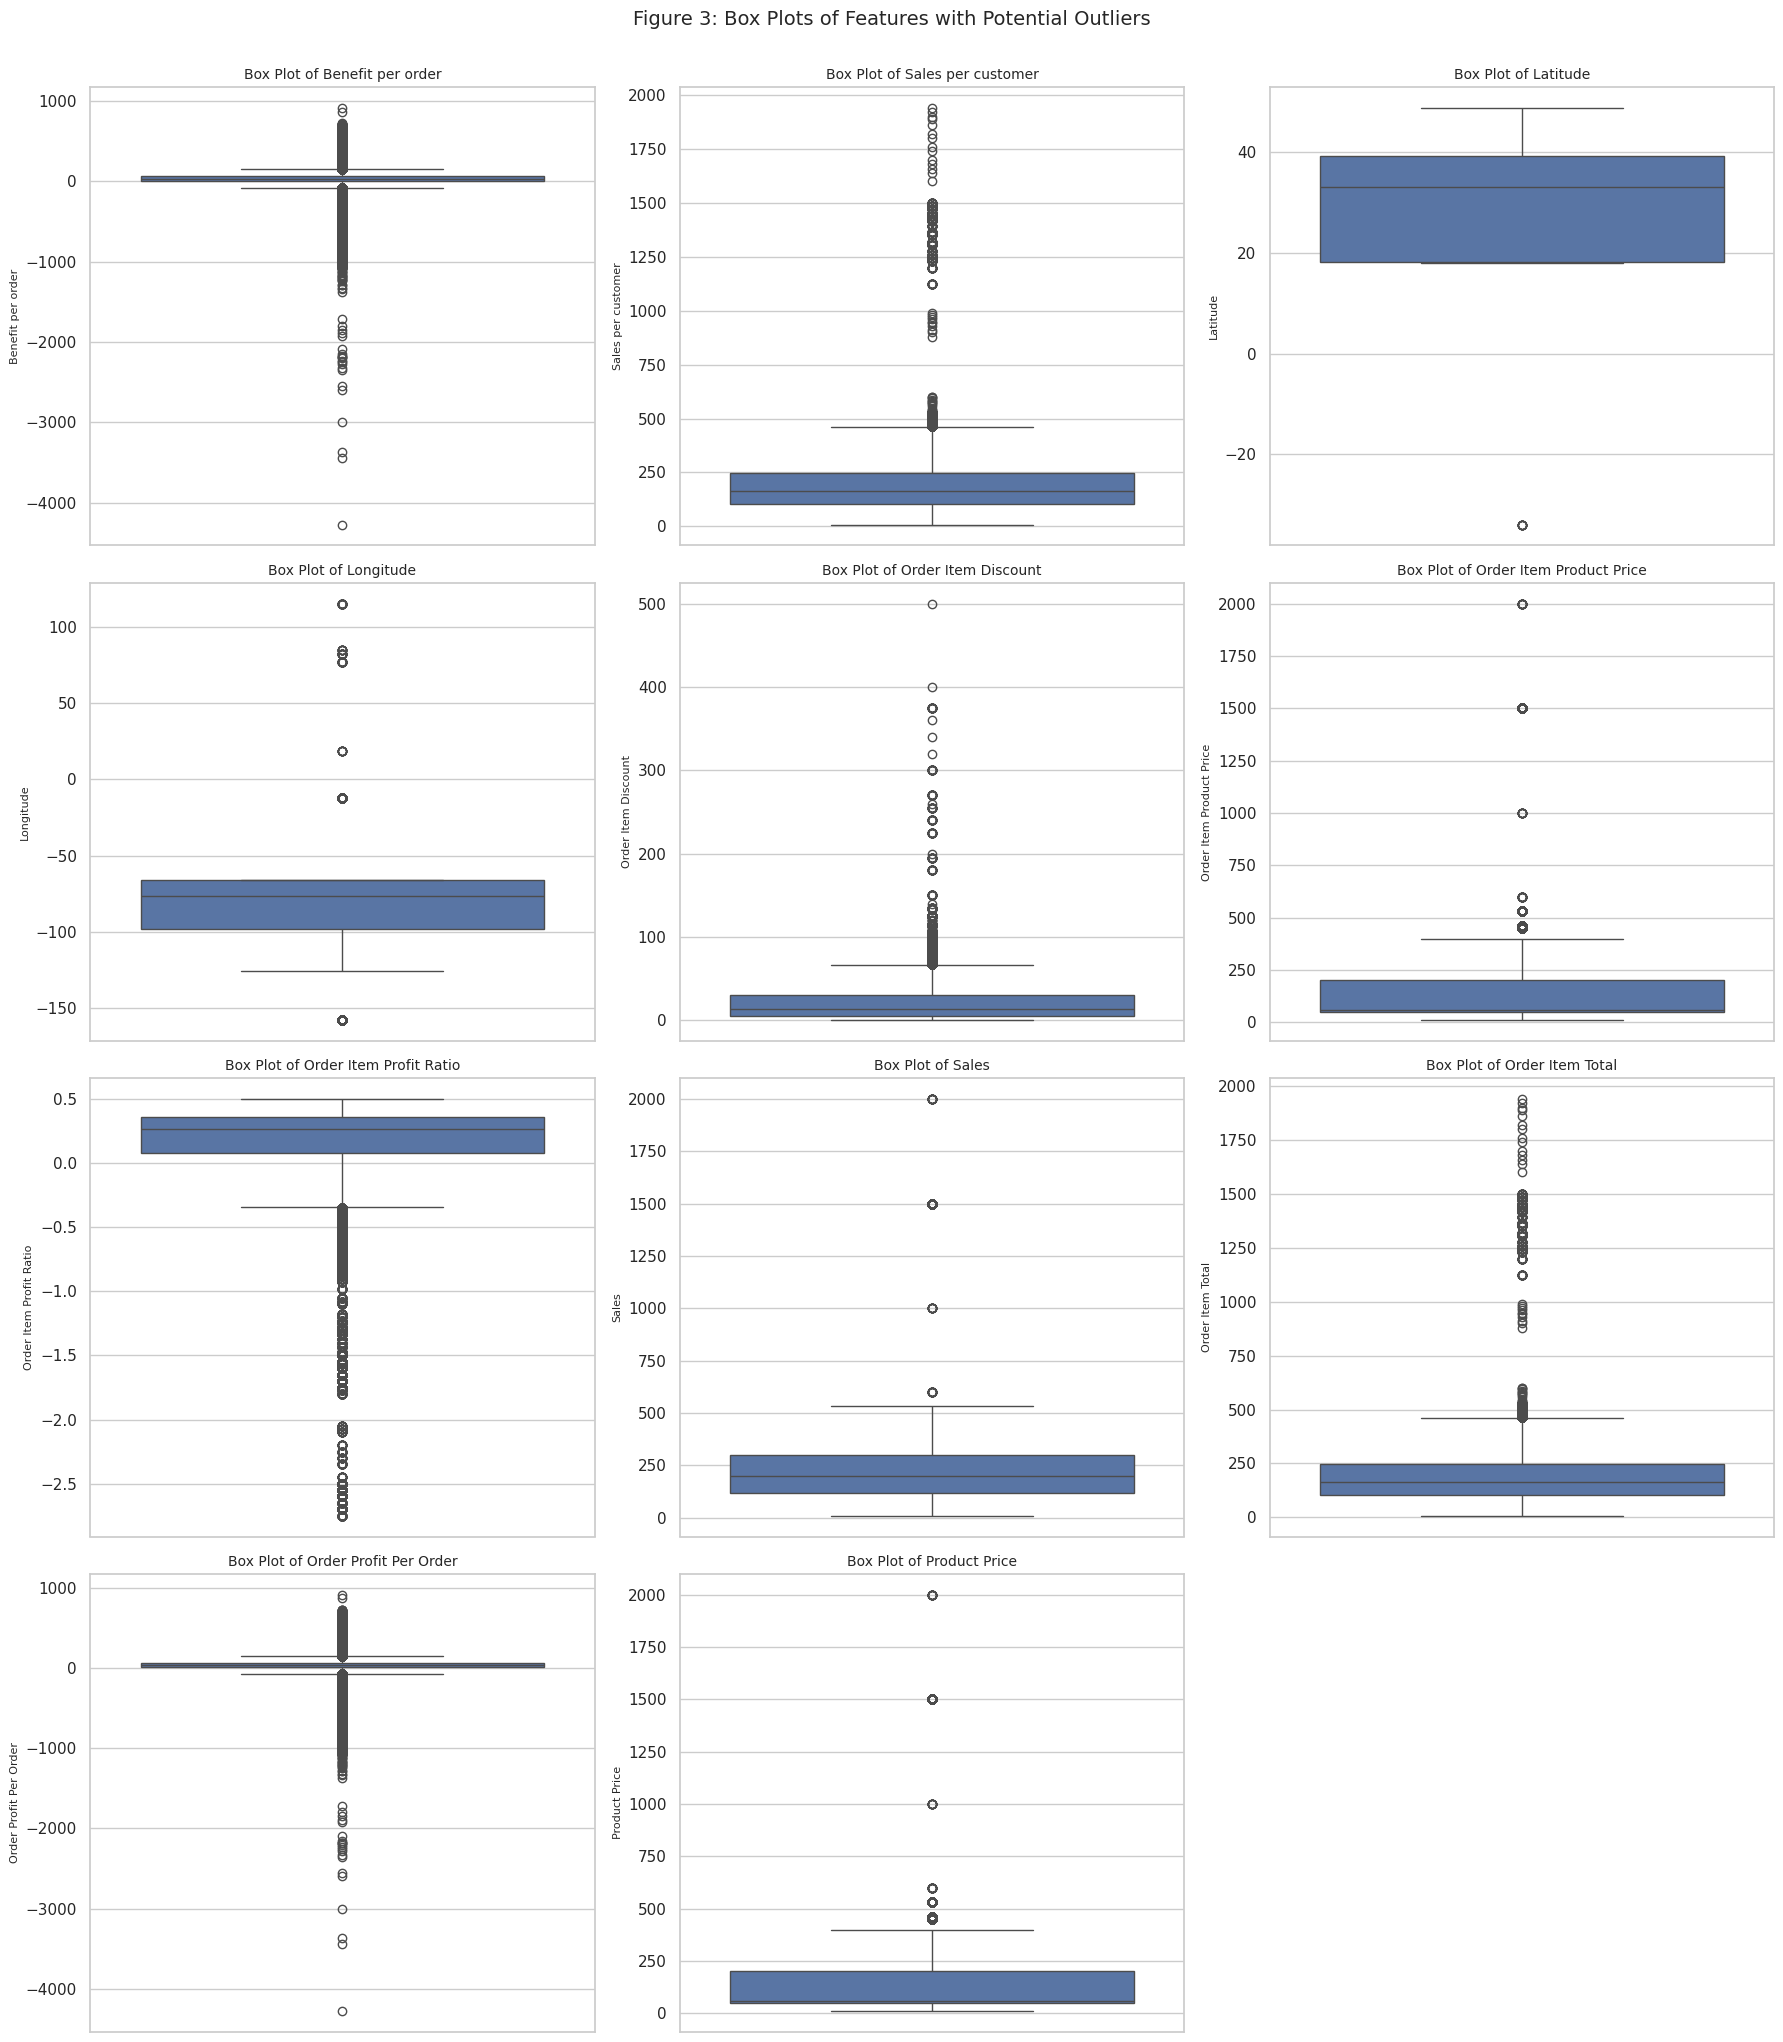

Figure 3: Box plots illustrating the distribution and presence of outliers for features identified with extreme values. Outliers are typically represented as individual points beyond the 'whiskers' of the box plot.


In [ ]:
numerical_cols = dataco_df.select_dtypes(include=np.number).columns
exclude_for_outliers = ['Customer Id', 'Order Id', 'Order Item Id', 'Product Card Id', 'Category Id', 'Department Id', 'Product Category Id', 'Late_delivery_risk', 'Product Status', 'Customer Zipcode', 'Order Zipcode', 'Year']
outlier_check_cols = [col for col in numerical_cols if col not in exclude_for_outliers]

outlier_features = {}

for col in outlier_check_cols:
    Q1 = dataco_df[col].quantile(0.25)
    Q3 = dataco_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = dataco_df[(dataco_df[col] < lower_bound) | (dataco_df[col] > upper_bound)][col]

    if not outliers.empty:
        outlier_features[col] = {
            'count': len(outliers),
            'percentage': (len(outliers) / len(dataco_df)) * 100,
            'example_values': outliers.head(5).tolist()
        }

if outlier_features:
    print("Features with potential outliers (based on IQR method):\n")
    for feature, info in outlier_features.items():
        print(f"- {feature}: {info['count']} outliers ({info['percentage']:.2f}% of data). Example values: {info['example_values']}")

    num_outlier_plots = len(outlier_features)
    if num_outlier_plots > 0:
        num_cols_bp = 3
        num_rows_bp = (num_outlier_plots + num_cols_bp - 1) // num_cols_bp

        fig_bp, axes_bp = plt.subplots(num_rows_bp, num_cols_bp, figsize=(num_cols_bp * 6, num_rows_bp * 5))
        axes_bp = axes_bp.flatten()

        for i, (col, info) in enumerate(outlier_features.items()):
            sns.boxplot(y=dataco_df[col], ax=axes_bp[i])
            axes_bp[i].set_title(f'Box Plot of {col}', fontsize=10)
            axes_bp[i].set_ylabel(col, fontsize=8)

        for j in range(i + 1, len(axes_bp)):
            fig_bp.delaxes(axes_bp[j])

        plt.tight_layout()
        plt.suptitle('Figure 3: Box Plots of Features with Potential Outliers', y=1.02, fontsize=14)
        plt.show()
        print("Figure 3: Box plots illustrating the distribution and presence of outliers for features identified with extreme values. Outliers are typically represented as individual points beyond the 'whiskers' of the box plot.")

## 🔹 Step 5. Univariate — Histograms

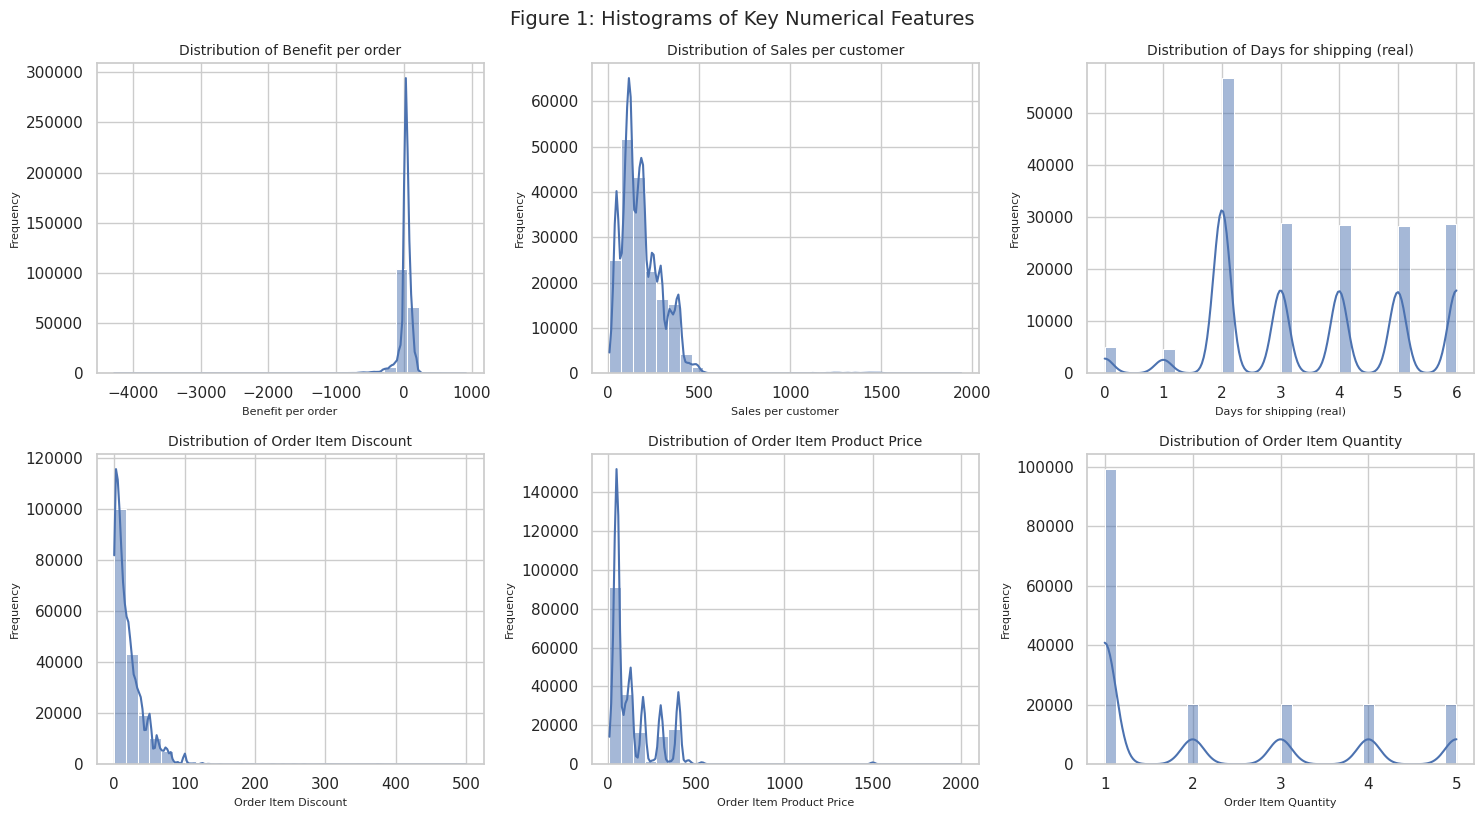

Figure 1: Histograms showing the distribution of selected key numerical features. The charts provide insights into the central tendency, spread, and shape of the data for each feature, and help identify potential outliers or skewness.


In [ ]:
numerical_cols = dataco_df.select_dtypes(include=['int64', 'float64']).columns
exclude_cols = ['Customer Id', 'Order Id', 'Order Item Id', 'Product Card Id', 'Category Id', 'Department Id', 'Product Category Id', 'Late_delivery_risk', 'Product Status', 'Customer Zipcode', 'Order Zipcode']
histogram_cols = [col for col in numerical_cols if col not in exclude_cols]

key_features = [
    'Benefit per order',
    'Sales per customer',
    'Days for shipping (real)',
    'Order Item Discount',
    'Order Item Product Price',
    'Order Item Quantity'
]

key_features = [f for f in key_features if f in histogram_cols and f in dataco_df.columns]

if not key_features:
    print("No suitable numerical features found for histograms after exclusions.")
else:
    num_plots = len(key_features)
    num_cols = 3
    num_rows = (num_plots + num_cols - 1) // num_cols

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 4))
    axes = axes.flatten()

    for i, col in enumerate(key_features):
        sns.histplot(dataco_df[col].dropna(), kde=True, ax=axes[i], bins=30)
        axes[i].set_title(f'Distribution of {col}', fontsize=10)
        axes[i].set_xlabel(col, fontsize=8)
        axes[i].set_ylabel('Frequency', fontsize=8)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.suptitle('Figure 1: Histograms of Key Numerical Features', y=1.02, fontsize=14)
    plt.show()

    print("Figure 1: Histograms showing the distribution of selected key numerical features. The charts provide insights into the central tendency, spread, and shape of the data for each feature, and help identify potential outliers or skewness.")

## 🔹 Step 6. Bivariate — Correlation Matrix

Correlations with 'Late_delivery_risk':


,Late_delivery_risk
Late_delivery_risk,1.000000
Days for shipping (real),0.401415
Customer Zipcode,0.003148
Latitude,0.000679
Order Item Discount Rate,0.000404
Order Item Quantity,-0.000139
Order Item Discount,-0.000750
Longitude,-0.001915
Product Price,-0.002175
Order Item Product Price,-0.002175


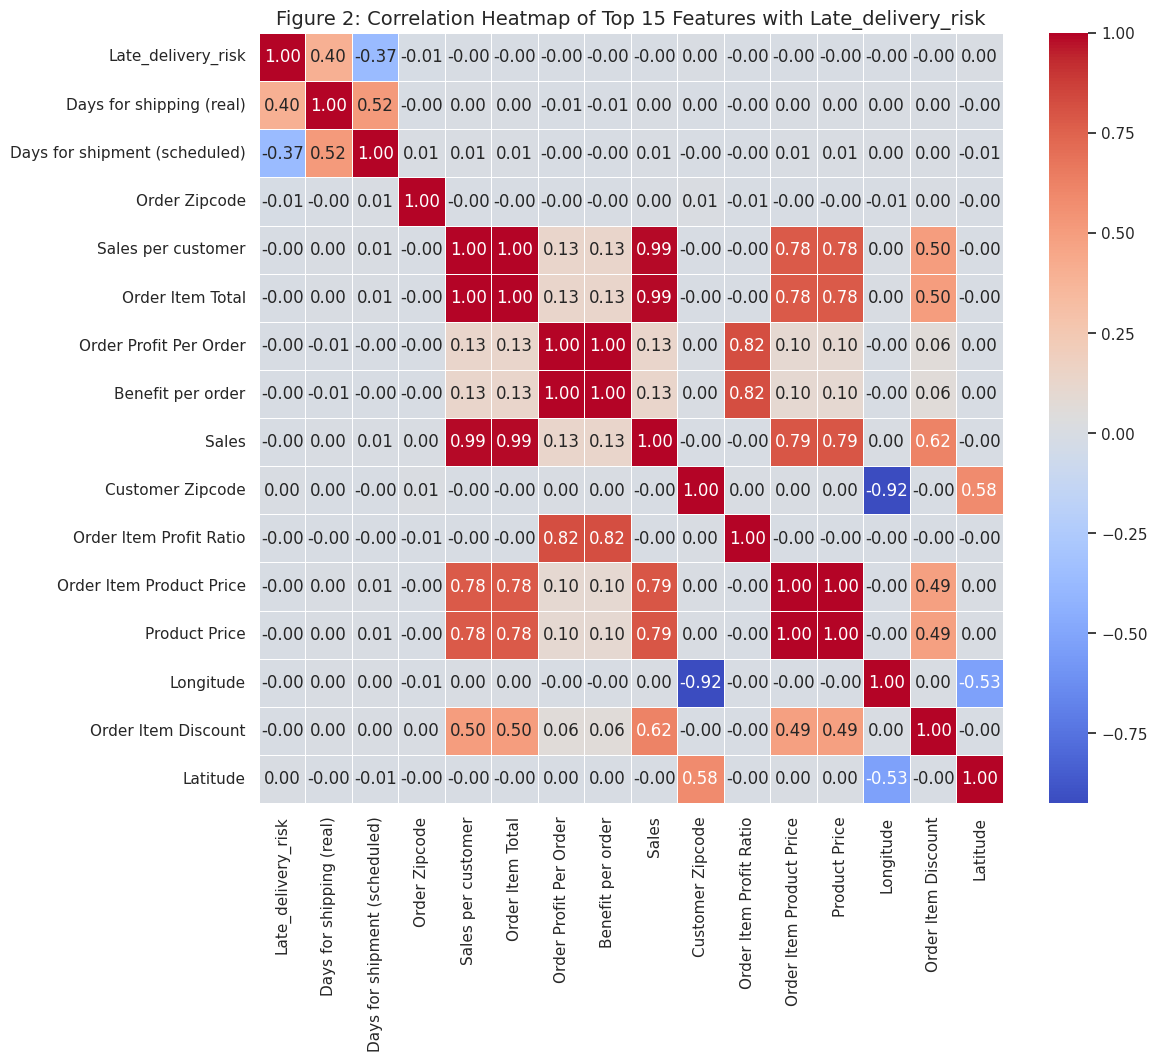

Figure 2: Heatmap showing the correlation between Late_delivery_risk and the top 15 most correlated features. This visualization helps in understanding the linear relationships between features and the target, and among features themselves.


In [ ]:
if target_variable not in dataco_df.columns:
    print(f"Target variable '{target_variable}' not found in DataFrame. Cannot proceed with correlation matrix.")
else:
    numerical_cols = dataco_df.select_dtypes(include=np.number).columns
    exclude_ids = ['Customer Id', 'Order Id', 'Order Item Id', 'Product Card Id', 'Category Id', 'Department Id', 'Product Category Id']
    corr_cols = [col for col in numerical_cols if col not in exclude_ids]

    if target_variable not in corr_cols:
        corr_cols.append(target_variable)

    correlation_matrix = dataco_df[corr_cols].corr()

    target_correlations = correlation_matrix[target_variable].sort_values(ascending=False)
    print(f"Correlations with '{target_variable}':")
    display(target_correlations)

    abs_corr_with_target = target_correlations.drop(labels=[target_variable]).abs().sort_values(ascending=False)
    top_correlated_features = abs_corr_with_target.head(top_n).index.tolist()

    if len(top_correlated_features) > 0:
        heatmap_cols = [target_variable] + top_correlated_features
        heatmap_cols = [col for col in heatmap_cols if col in dataco_df.columns]

        plt.figure(figsize=(12, 10))
        sns.heatmap(dataco_df[heatmap_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
        plt.title(f'Figure 2: Correlation Heatmap of Top {len(top_correlated_features)} Features with {target_variable}', fontsize=14)
        plt.show()
        print(f"Figure 2: Heatmap showing the correlation between {target_variable} and the top {len(top_correlated_features)} most correlated features. This visualization helps in understanding the linear relationships between features and the target, and among features themselves.")
    else:
        print("No sufficiently correlated numerical features found to generate a heatmap.")

In [ ]:
dataco_df["Order_Date"] = pd.to_datetime(
    dataco_df["order date (DateOrders)"],
    errors="coerce"
)

dataco_df["Year"] = dataco_df["Order_Date"].dt.year

annual_late_delivery = (
    dataco_df
    .dropna(subset=["Year", "Late_delivery_risk"])
    .groupby("Year", as_index=False)["Late_delivery_risk"]
    .mean()
    .rename(columns={
        "Late_delivery_risk": "Annual_Late_Delivery_Rate"
    })
)

annual_late_delivery

,Year,Annual_Late_Delivery_Rate
0,2015,0.548635
1,2016,0.550695
2,2017,0.544477
3,2018,0.562883


### 🔹 Delivery Risk by Country and Year
Exploring how geographical performance has evolved over time by calculating the mean `Late_delivery_risk` per country per year.

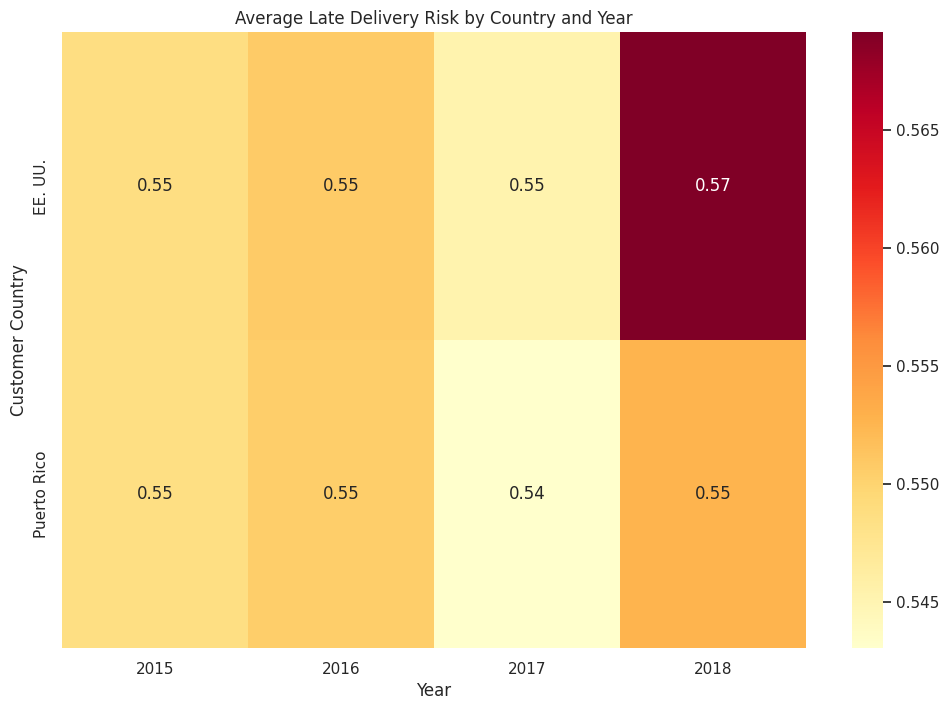

Summary of Findings:
Highest average risk by country:
Customer Country
EE. UU.        0.548702
Puerto Rico    0.547634
Name: Late_delivery_risk, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

country_year_risk = dataco_df.groupby(['Customer Country', 'Year'])['Late_delivery_risk'].mean().unstack()

plt.figure(figsize=(12, 8))
sns.heatmap(country_year_risk, annot=True, cmap='YlOrRd', fmt='.2f')

plt.title('Average Late Delivery Risk by Country and Year')
plt.xlabel('Year')
plt.ylabel('Customer Country')
plt.show()

print("Summary of Findings:")
country_avg = dataco_df.groupby('Customer Country')['Late_delivery_risk'].mean().sort_values(ascending=False)
print(f"Highest average risk by country:\n{country_avg.head(3)}")

### 🔹 Daily Time Series: Sales and Delivery Risk
Analyzing the temporal patterns of financial performance and operational risk by aggregating data to a daily level.

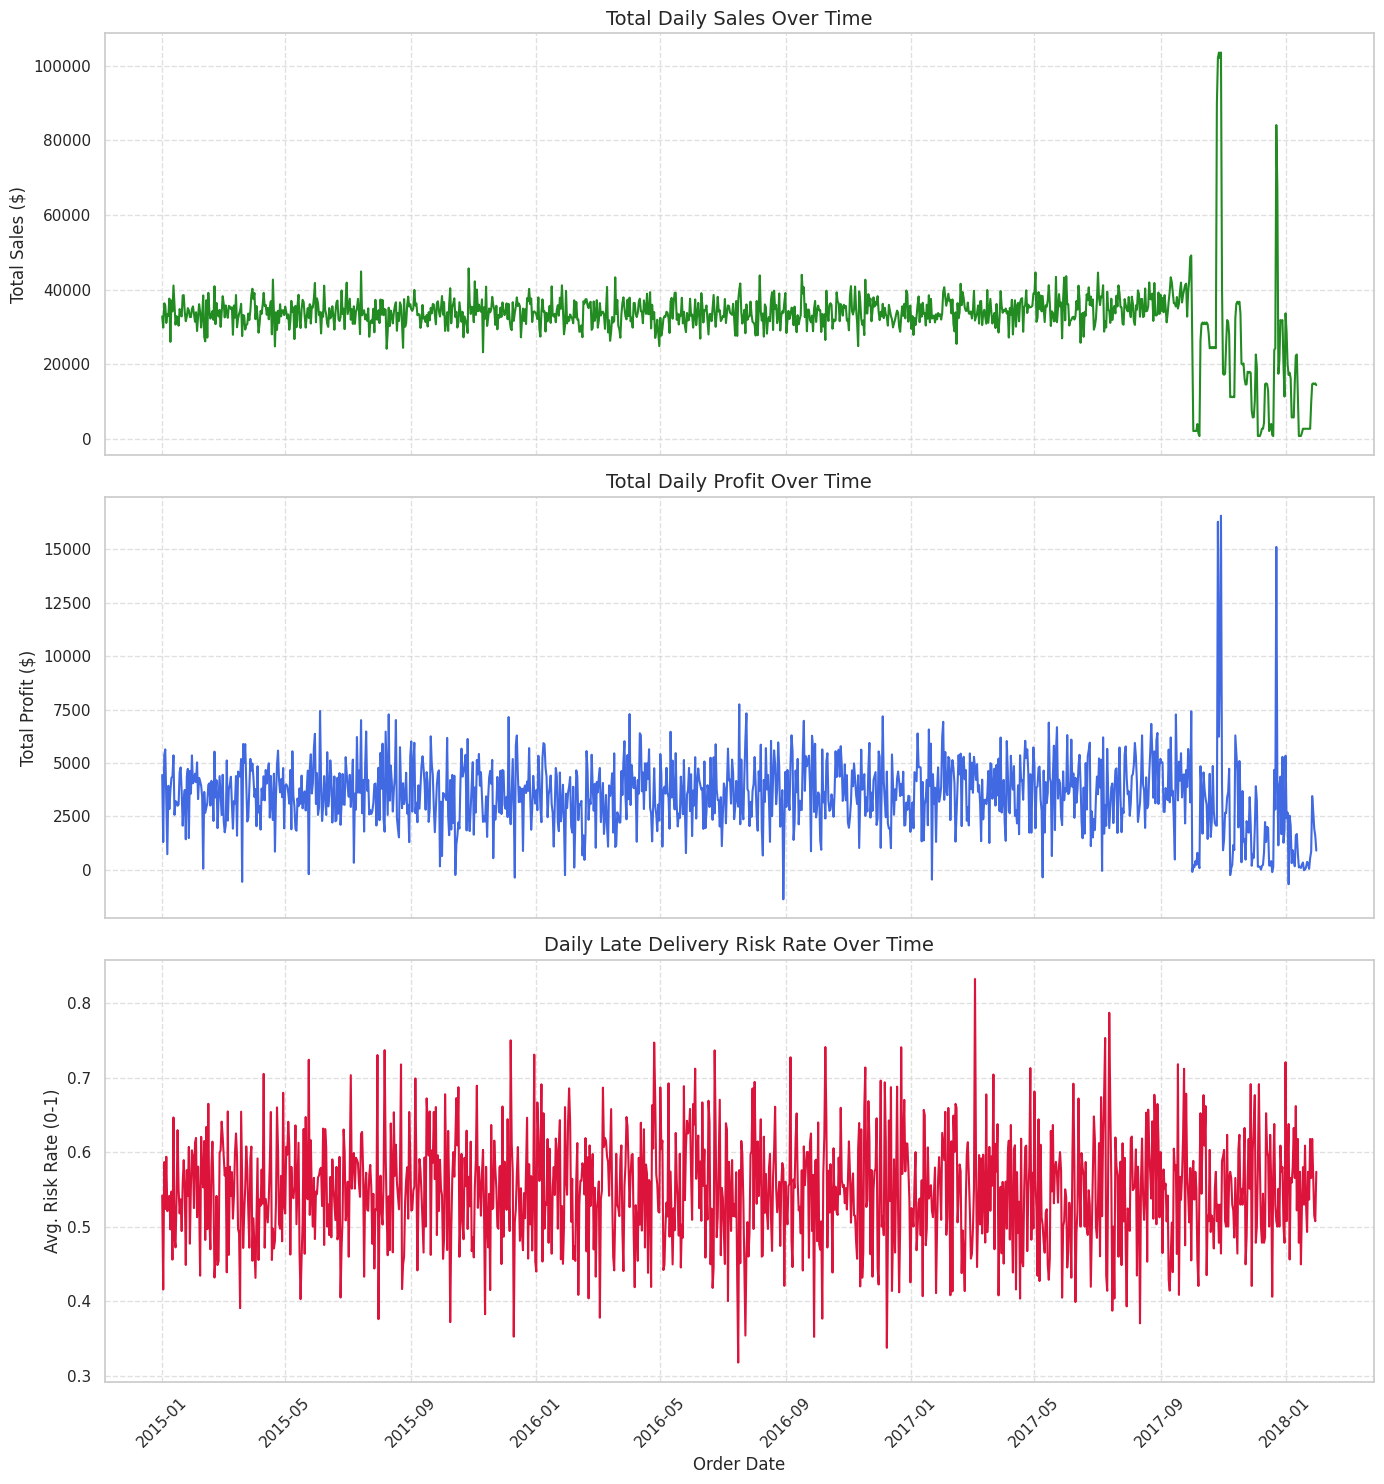

In [ ]:
daily_metrics = dataco_df.groupby(dataco_df['Order_Date'].dt.date).agg({
    'Sales': 'sum',
    'Late_delivery_risk': 'mean',
    'Order Profit Per Order': 'sum'
}).reset_index()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 15), sharex=True)

sns.lineplot(data=daily_metrics, x='Order_Date', y='Sales', ax=ax1, color='forestgreen')
ax1.set_title('Total Daily Sales Over Time', fontsize=14)
ax1.set_ylabel('Total Sales ($)')
ax1.grid(True, linestyle='--', alpha=0.6)

sns.lineplot(data=daily_metrics, x='Order_Date', y='Order Profit Per Order', ax=ax2, color='royalblue')
ax2.set_title('Total Daily Profit Over Time', fontsize=14)
ax2.set_ylabel('Total Profit ($)')
ax2.grid(True, linestyle='--', alpha=0.6)

sns.lineplot(data=daily_metrics, x='Order_Date', y='Late_delivery_risk', ax=ax3, color='crimson')
ax3.set_title('Daily Late Delivery Risk Rate Over Time', fontsize=14)
ax3.set_ylabel('Avg. Risk Rate (0-1)')
ax3.grid(True, linestyle='--', alpha=0.6)

plt.xlabel('Order Date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
def get_delay_perc(df, column, top_n=10):
    """Calculates late delivery percentage for a specific categorical column."""
    top_values = df[column].value_counts().nlargest(top_n).index
    filtered_df = df[df[column].isin(top_values)]

    delay_df = filtered_df.groupby(column)['Late_delivery_risk'].agg(['mean', 'count']).reset_index()
    delay_df['delay_per'] = delay_df['mean'] * 100
    return delay_df.sort_values('delay_per', ascending=False)

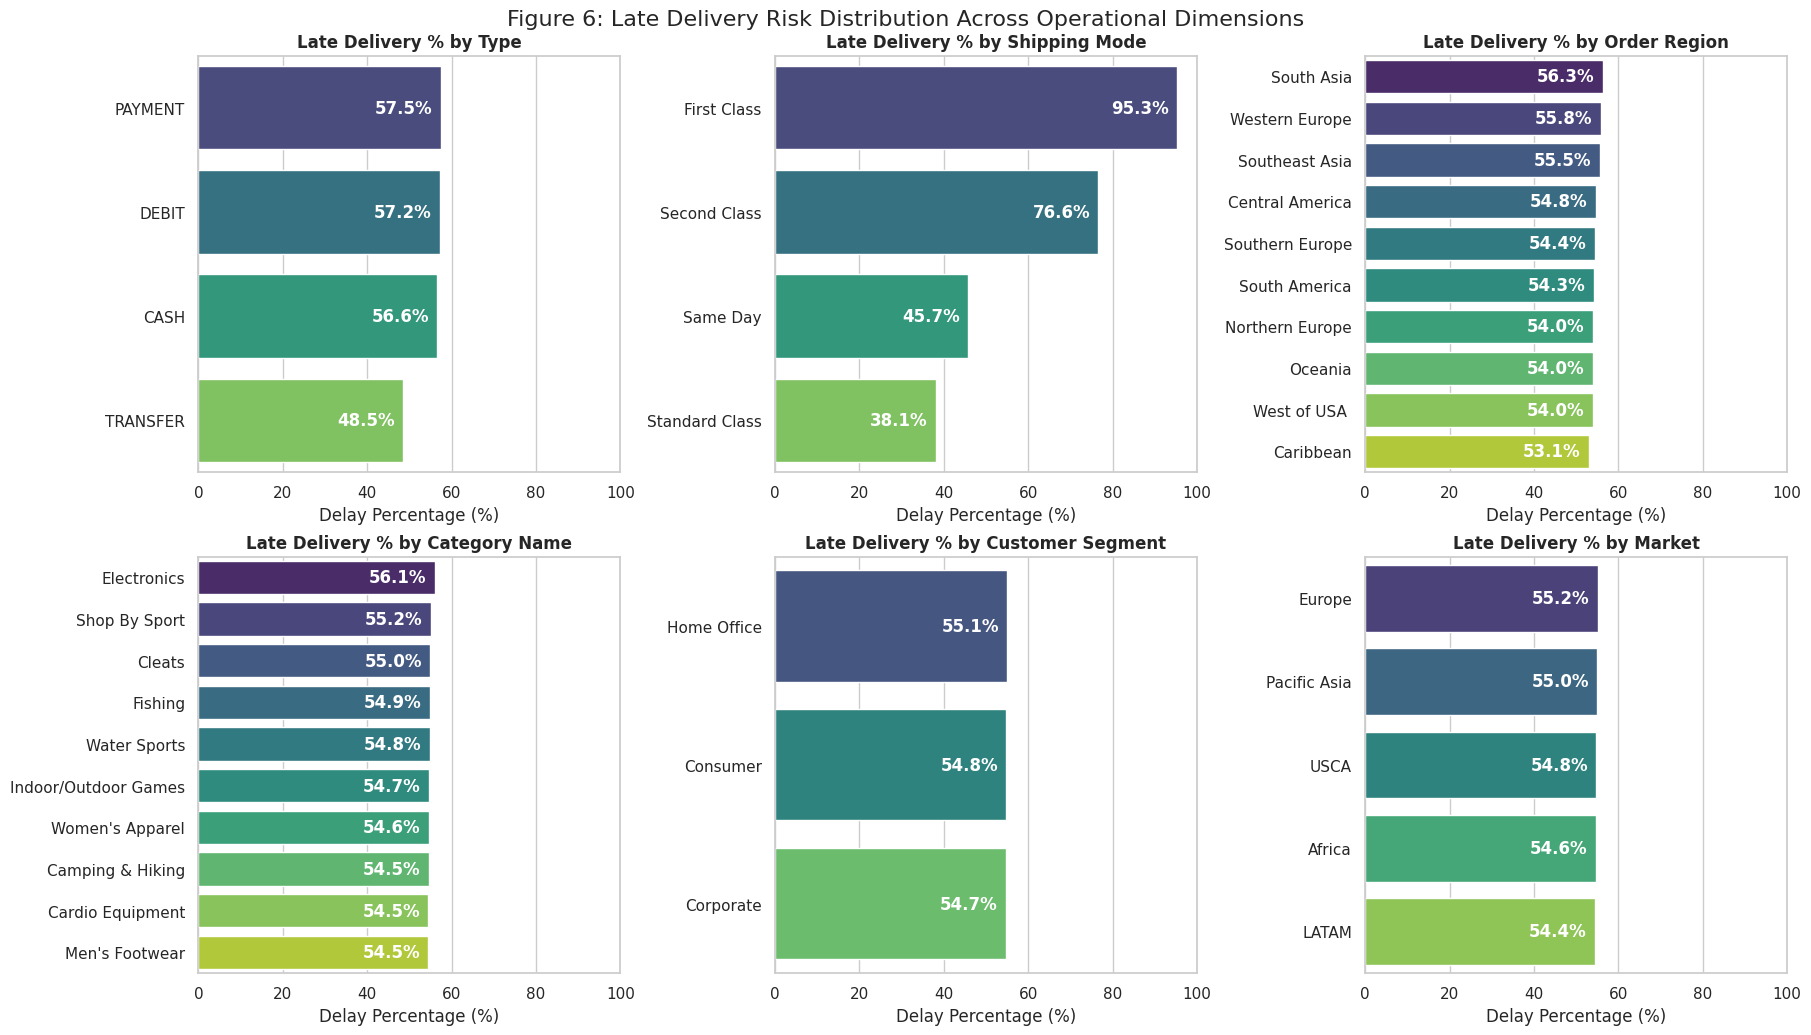

In [ ]:
categories = ['Type', 'Shipping Mode', 'Order Region', 'Category Name', 'Customer Segment', 'Market']

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.flatten()

for i, cat in enumerate(categories):
    ax = axes[i]
    cat_df = get_delay_perc(dataco_df, cat)

    sns.barplot(data=cat_df, x='delay_per', y=cat, ax=ax, palette='viridis', hue=cat, legend=False)

    ax.set_title(f'Late Delivery % by {cat}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Delay Percentage (%)')
    ax.set_ylabel('')
    ax.set_xlim(0, 100)

    # Add data labels inside the bars
    for p in ax.patches:
        width = p.get_width()
        ax.text(width - 2, p.get_y() + p.get_height() / 2,
                f'{width:.1f}%', va='center', ha='right', color='white', fontweight='bold')

plt.suptitle('Figure 6: Late Delivery Risk Distribution Across Operational Dimensions', fontsize=16, y=1.02)
plt.show()

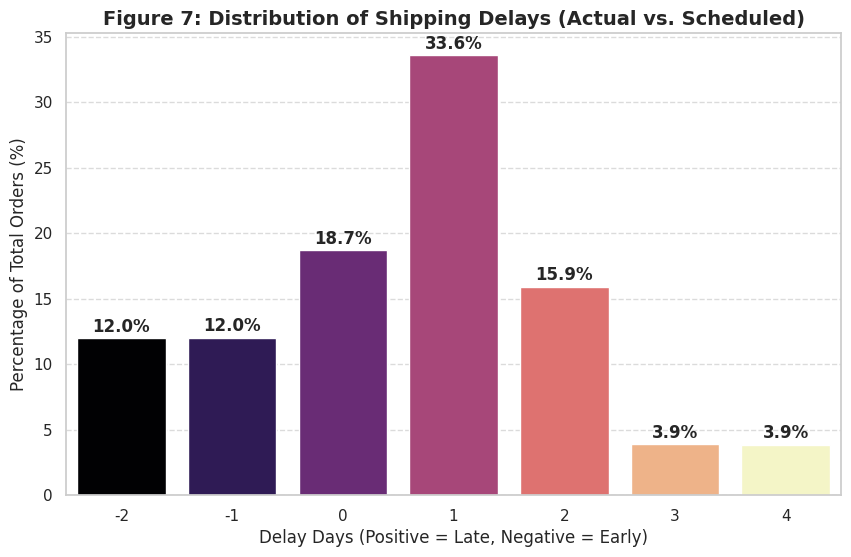

,delay,percentage
0,-2,12.002061
1,-1,12.020895
2,0,18.697755
3,1,33.595910
4,2,15.908575
5,3,3.906514
6,4,3.868291


In [ ]:
dataco_df['delay'] = dataco_df['Days for shipping (real)'] - dataco_df['Days for shipment (scheduled)']

delay_counts = dataco_df['delay'].value_counts(normalize=True).sort_index() * 100
delay_distribution = delay_counts.reset_index()
delay_distribution.columns = ['delay', 'percentage']

plt.figure(figsize=(10, 6))
sns.barplot(data=delay_distribution, x='delay', y='percentage', palette='magma', hue='delay', legend=False)

plt.title('Figure 7: Distribution of Shipping Delays (Actual vs. Scheduled)', fontsize=14, fontweight='bold')
plt.xlabel('Delay Days (Positive = Late, Negative = Early)')
plt.ylabel('Percentage of Total Orders (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, p in enumerate(delay_distribution['percentage']):
    plt.text(i, p + 0.5, f'{p:.1f}%', ha='center', fontweight='bold')

plt.show()

display(delay_distribution)

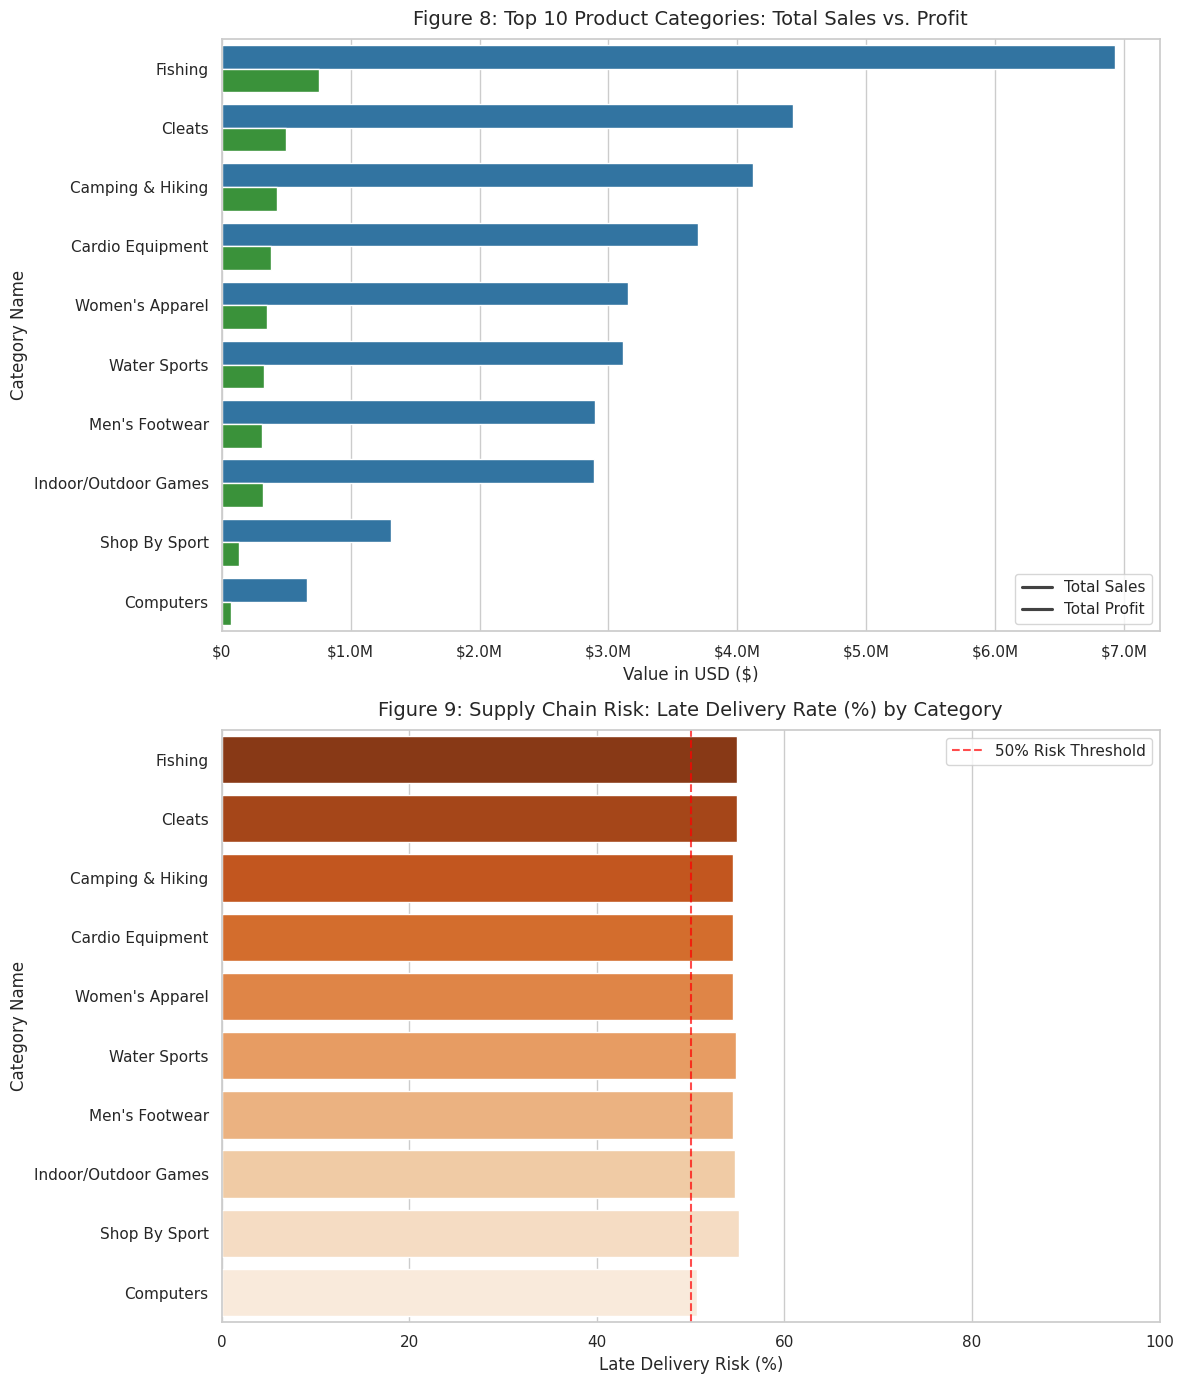

In [ ]:
category_analysis = dataco_df.groupby('Category Name').agg({
    'Sales': 'sum',
    'Order Profit Per Order': 'sum',
    'Late_delivery_risk': 'mean'
}).reset_index()

category_analysis.columns = ['Category Name', 'Total_Sales', 'Total_Profit', 'Late_Delivery_Rate']
category_analysis['Late_Delivery_Rate'] = category_analysis['Late_Delivery_Rate'] * 100

category_analysis = category_analysis.sort_values(by='Total_Sales', ascending=False).head(10)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(12, 14))

melted_df = category_analysis.melt(
    id_vars='Category Name',
    value_vars=['Total_Sales', 'Total_Profit'],
    var_name='Metric',
    value_name='Amount'
)

sns.barplot(
    ax=axes[0],
    x='Amount',
    y='Category Name',
    hue='Metric',
    data=melted_df,
    palette=['#1f77b4', '#2ca02c']
)

axes[0].set_title('Figure 8: Top 10 Product Categories: Total Sales vs. Profit', fontsize=14, pad=10)
axes[0].set_xlabel('Value in USD ($)')
axes[0].set_ylabel('Category Name')
axes[0].legend(['Total Sales', 'Total Profit'])

axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x*1e-6:.1f}M' if x >= 1e6 else f'${x:,.0f}'))

sns.barplot(
    ax=axes[1],
    x='Late_Delivery_Rate',
    y='Category Name',
    data=category_analysis,
    palette='Oranges_r',
    hue='Category Name',
    legend=False
)

axes[1].axvline(50, color='red', linestyle='--', alpha=0.7, label='50% Risk Threshold')
axes[1].set_title('Figure 9: Supply Chain Risk: Late Delivery Rate (%) by Category', fontsize=14, pad=10)
axes[1].set_xlabel('Late Delivery Risk (%)')
axes[1].set_ylabel('Category Name')
axes[1].set_xlim(0, 100)
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# ARTHUNYA — Financial Layer (Taiwan Bankruptcy Dataset)
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])

# ---- 1. Basic inspection ----
print("Shape:", df.shape)
print(df.columns.tolist()[:10], "...")
df.head()

Saving data.csv to data.csv
Shape: (6819, 96)
['Bankrupt?', ' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue'] ...


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [ ]:
# ---- 2. Confirm target column & class balance ----
target_col = "Bankrupt?"  # check colum name
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True) * 100)

Bankrupt?
0    6599
1     220
Name: count, dtype: int64
Bankrupt?
0    96.77372
1     3.22628
Name: proportion, dtype: float64


In [ ]:
# ---- 3. Missing values ----
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_pct", ascending=False)

,missing_count,missing_pct


In [ ]:
# ---- 4. Correlation with target bankruptcy) ----
correlations = df.corr(numeric_only=True)[target_col].sort_values(ascending=False)
print("Top 10 positively correlated:")
print(correlations.head(11))
print("\nTop 10 negatively correlated:")
print(correlations.tail(10))

Top 10 positively correlated:
Bankrupt?                               1.000000
 Debt ratio %                           0.250161
 Current Liability to Assets            0.194494
 Borrowing dependency                   0.176543
 Current Liability to Current Assets    0.171306
 Liability to Equity                    0.166812
 Current Liabilities/Equity             0.153828
 Current Liability to Equity            0.153828
 Liability-Assets Flag                  0.139212
 Total expense/Assets                   0.139049
 Equity to Long-term Liability          0.139014
Name: Bankrupt?, dtype: float64

Top 10 negatively correlated:
Per Share Net profit before tax (Yuan ¥)                  -0.201395
Net profit before tax/Paid-in capital                     -0.207857
Retained Earnings to Total Assets                         -0.217779
Persistent EPS in the Last Four Seasons                   -0.219560
Net worth/Assets                                          -0.250161
ROA(C) before interest and d

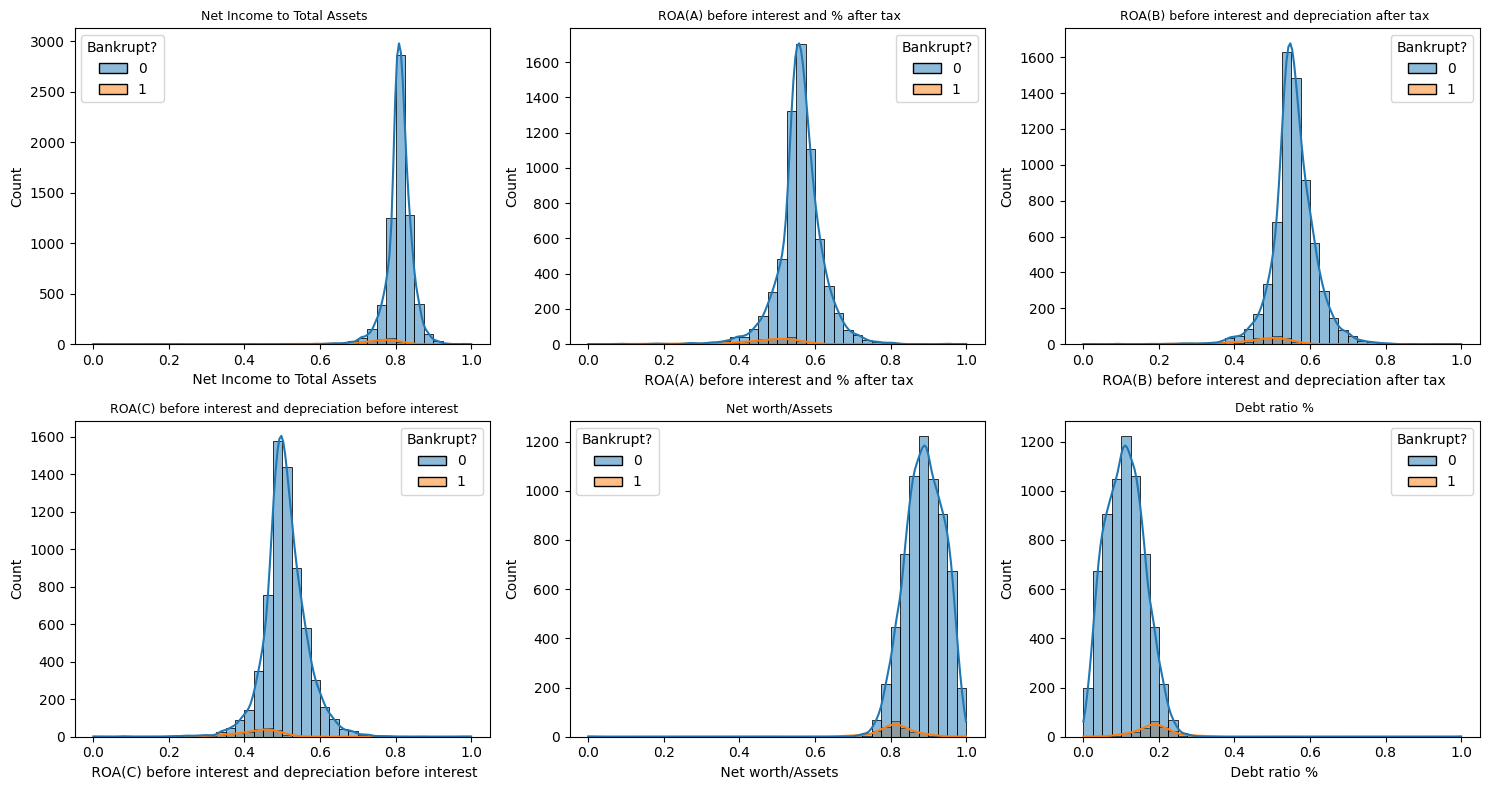

In [ ]:
# ---- 5. Histograms ratio  ----
top_features = correlations.abs().sort_values(ascending=False).index[1:7]  # cut 6 first targets

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), top_features):
    sns.histplot(data=df, x=col, hue=target_col, bins=40, ax=ax, kde=True)
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

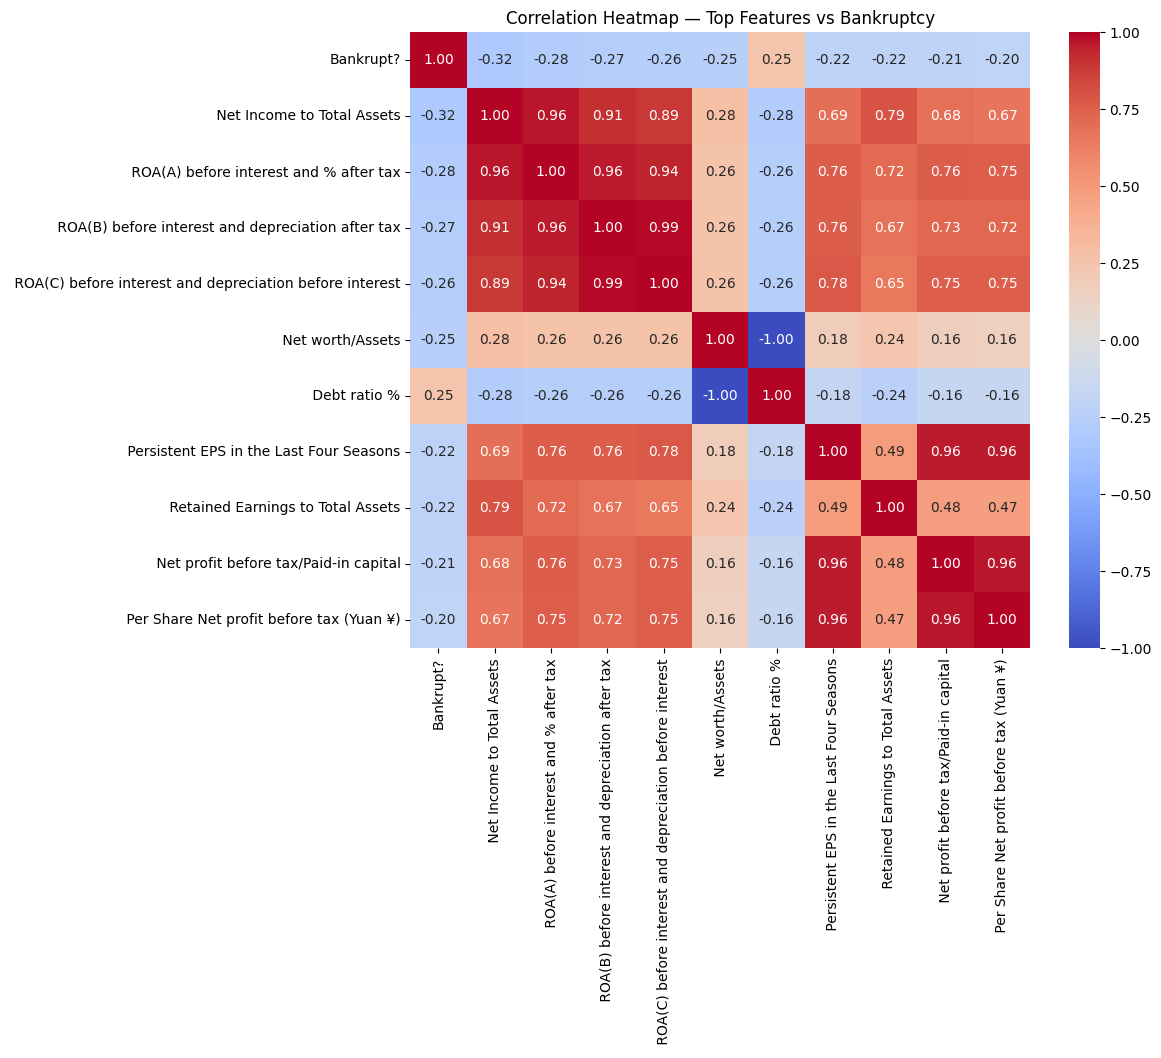

In [ ]:
# ---- 6. Correlation heatmap (Only top features) ----
top_corr_features = correlations.abs().sort_values(ascending=False).index[:11]
plt.figure(figsize=(10, 8))
sns.heatmap(df[top_corr_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap — Top Features vs Bankruptcy")
plt.show()

In [ ]:
# ---- 7. Outlier check ----
for col in top_features:
    print(f"{col}: min={df[col].min():.3f}, max={df[col].max():.3f}, "
          f"mean={df[col].mean():.3f}, std={df[col].std():.3f}")

 Net Income to Total Assets: min=0.000, max=1.000, mean=0.808, std=0.040
 ROA(A) before interest and % after tax: min=0.000, max=1.000, mean=0.559, std=0.066
 ROA(B) before interest and depreciation after tax: min=0.000, max=1.000, mean=0.554, std=0.062
 ROA(C) before interest and depreciation before interest: min=0.000, max=1.000, mean=0.505, std=0.061
 Net worth/Assets: min=0.000, max=1.000, mean=0.887, std=0.054
 Debt ratio %: min=0.000, max=1.000, mean=0.113, std=0.054


In [ ]:
# ---- 7B. Check normalization range across ALL numeric columns ----
numeric_cols = df.select_dtypes(include=[np.number]).columns
numeric_cols = numeric_cols.drop(target_col)  # not include target column

range_summary = pd.DataFrame({
    "min": df[numeric_cols].min(),
    "max": df[numeric_cols].max()
})

# check column [0, 1] match (if so, normalized)
range_summary["normalized_0_1"] = (
    (range_summary["min"] >= 0) & (range_summary["max"] <= 1)
)

print(f"Total numeric columns (excl. target): {len(numeric_cols)}")
print(f"Columns within [0, 1] range: {range_summary['normalized_0_1'].sum()}")
print(f"Columns NOT within [0, 1] range: {(~range_summary['normalized_0_1']).sum()}")

print("\n--- Columns that are NOT normalized (min/max outside [0,1]) ---")
not_normalized = range_summary[~range_summary["normalized_0_1"]]
print(not_normalized)

Total numeric columns (excl. target): 95
Columns within [0, 1] range: 71
Columns NOT within [0, 1] range: 24

--- Columns that are NOT normalized (min/max outside [0,1]) ---
                                       min           max  normalized_0_1
Operating Expense Rate                 0.0  9.990000e+09           False
Research and development expense rate  0.0  9.980000e+09           False
Interest-bearing debt interest rate    0.0  9.900000e+08           False
Revenue Per Share (Yuan ¥)             0.0  3.020000e+09           False
Total Asset Growth Rate                0.0  9.990000e+09           False
Net Value Growth Rate                  0.0  9.330000e+09           False
Current Ratio                          0.0  2.750000e+09           False
Quick Ratio                            0.0  9.230000e+09           False
Total debt/Total net worth             0.0  9.940000e+09           False
Accounts Receivable Turnover           0.0  9.740000e+09           False
Average Collection Days

In [ ]:
# ---- 7C. (which column is not normalize) what kind of column info ----
if len(not_normalized) > 0:
    print(not_normalized.index.tolist())

[' Operating Expense Rate', ' Research and development expense rate', ' Interest-bearing debt interest rate', ' Revenue Per Share (Yuan ¥)', ' Total Asset Growth Rate', ' Net Value Growth Rate', ' Current Ratio', ' Quick Ratio', ' Total debt/Total net worth', ' Accounts Receivable Turnover', ' Average Collection Days', ' Inventory Turnover Rate (times)', ' Fixed Assets Turnover Frequency', ' Revenue per person', ' Allocation rate per person', ' Quick Assets/Current Liability', ' Cash/Current Liability', ' Inventory/Current Liability', ' Long-term Liability to Current Assets', ' Current Asset Turnover Rate', ' Quick Asset Turnover Rate', ' Cash Turnover Rate', ' Fixed Assets to Assets', ' Total assets to GNP price']


In [ ]:
# ---- 7D. check sentinel value or just outlier ----
suspect_cols = not_normalized.index.tolist()

for col in suspect_cols[:5]:  # example 5 column
    print(f"\n--- {col} ---")
    print(df[col].describe(percentiles=[.25, .5, .75, .95, .99, .999]))
    extreme_count = (df[col] > df[col].quantile(0.999)).sum()
    print(f"Rows above 99.9th percentile: {extreme_count} out of {len(df)}")


---  Operating Expense Rate ---
count    6.819000e+03
mean     1.995347e+09
std      3.237684e+09
min      0.000000e+00
25%      1.566874e-04
50%      2.777589e-04
75%      4.145000e+09
95%      8.950000e+09
99%      9.790000e+09
99.9%    9.970000e+09
max      9.990000e+09
Name:  Operating Expense Rate, dtype: float64
Rows above 99.9th percentile: 5 out of 6819

---  Research and development expense rate ---
count    6.819000e+03
mean     1.950427e+09
std      2.598292e+09
min      0.000000e+00
25%      1.281880e-04
50%      5.090000e+08
75%      3.450000e+09
95%      7.710000e+09
99%      9.440000e+09
99.9%    9.930000e+09
max      9.980000e+09
Name:  Research and development expense rate, dtype: float64
Rows above 99.9th percentile: 6 out of 6819

---  Interest-bearing debt interest rate ---
count    6.819000e+03
mean     1.644801e+07
std      1.082750e+08
min      0.000000e+00
25%      2.030203e-04
50%      3.210321e-04
75%      5.325533e-04
95%      1.260726e-03
99%      7.582000e

In [ ]:
# ---- 7E. count column abnormal ----
for col in suspect_cols:
    huge_count = (df[col] > 1000).sum()  # threshold if over 1000 = abnormal
    print(f"{col}: {huge_count} rows with value > 1000 (out of {len(df)})")

 Operating Expense Rate: 2282 rows with value > 1000 (out of 6819)
 Research and development expense rate: 4033 rows with value > 1000 (out of 6819)
 Interest-bearing debt interest rate: 221 rows with value > 1000 (out of 6819)
 Revenue Per Share (Yuan ¥): 5 rows with value > 1000 (out of 6819)
 Total Asset Growth Rate: 6017 rows with value > 1000 (out of 6819)
 Net Value Growth Rate: 2 rows with value > 1000 (out of 6819)
 Current Ratio: 1 rows with value > 1000 (out of 6819)
 Quick Ratio: 9 rows with value > 1000 (out of 6819)
 Total debt/Total net worth: 8 rows with value > 1000 (out of 6819)
 Accounts Receivable Turnover: 22 rows with value > 1000 (out of 6819)
 Average Collection Days: 18 rows with value > 1000 (out of 6819)
 Inventory Turnover Rate (times): 2946 rows with value > 1000 (out of 6819)
 Fixed Assets Turnover Frequency: 1228 rows with value > 1000 (out of 6819)
 Revenue per person: 2 rows with value > 1000 (out of 6819)
 Allocation rate per person: 12 rows with value 


# 👤 Section 2: Divya (Adjusted Sequence — Cross-Dataset Enrichment Task)


## 🔸 Step 1. Load & Aggregate
* **What to Do:** Load GSCPI monthly data; aggregate both risk labels (bankruptcy rate, late-delivery rate) to an annual level
* **Required Output:** Clean merged DataFrame ready for correlation

## 🔸 Step 2. Correlation Calculation
* **What to Do:** Calculate correlation between GSCPI and each annual risk rate
* **Required Output:** Two correlation coefficients (one per risk layer)

## 🔸 Step 3. Assumption Verification Summary
* **What to Do:** State clearly whether the result supports or fails to support the assumption from Frame the Problem (item 12)
* **Required Output:** 3–5 sentence written conclusion, with the actual numbers included either way

## 🔸 Step 4. Train/Test Split Methodology
* **What to Do:** Document the split percentage used, whether stratified sampling was applied, and confirm the test set was set aside before EDA began
* **Required Output:** Separate paragraph (not tied to a chart)

## GSCPI Enrichment and Assumption Verification

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

Saving gscpi_data.xls to gscpi_data.xls


In [ ]:
gscpi_file = list(uploaded.keys())[0]
print("Uploaded file:", gscpi_file)

Uploaded file: gscpi_data.xls


In [ ]:
excel_file = pd.ExcelFile(gscpi_file)

print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['GSCPI Monthly Data']


In [ ]:
gscpi_raw = pd.read_excel(
    gscpi_file,
    sheet_name=excel_file.sheet_names[0]
)

gscpi_raw.head(10)

,Date,GSCPI
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,31-Jan-1998,-1.092175
5,28-Feb-1998,-0.448778
6,31-Mar-1998,-0.051131
7,30-Apr-1998,-0.112958
8,31-May-1998,-0.423390
9,30-Jun-1998,-0.756850


In [ ]:
print("Shape:", gscpi_raw.shape)

print("\nColumns:")
print(gscpi_raw.columns.tolist())

print("\nData types:")
print(gscpi_raw.dtypes)

gscpi_raw.head()

Shape: (346, 2)

Columns:
['Date', 'GSCPI']

Data types:
Date      object
GSCPI    float64
dtype: object


,Date,GSCPI
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,31-Jan-1998,-1.092175


In [ ]:
gscpi_df = gscpi_raw.copy()

gscpi_df["Date"] = pd.to_datetime(
    gscpi_df["Date"],
    format="%d-%b-%Y",
    errors="coerce"
)

gscpi_df["GSCPI"] = pd.to_numeric(
    gscpi_df["GSCPI"],
    errors="coerce"
)

gscpi_df = (
    gscpi_df
    .dropna(subset=["Date", "GSCPI"])
    .sort_values("Date")
    .reset_index(drop=True)
)

gscpi_df.head()

,Date,GSCPI
0,1998-01-31,-1.092175
1,1998-02-28,-0.448778
2,1998-03-31,-0.051131
3,1998-04-30,-0.112958
4,1998-05-31,-0.423390


In [ ]:
print("Cleaned shape:", gscpi_df.shape)
print("Start date:", gscpi_df["Date"].min())
print("End date:", gscpi_df["Date"].max())

print("\nMissing values:")
print(gscpi_df.isnull().sum())

print("\nData types:")
print(gscpi_df.dtypes)

Cleaned shape: (342, 2)
Start date: 1998-01-31 00:00:00
End date: 2026-06-30 00:00:00

Missing values:
Date     0
GSCPI    0
dtype: int64

Data types:
Date     datetime64[ns]
GSCPI           float64
dtype: object


In [ ]:
gscpi_df["Month"] = gscpi_df["Date"].dt.to_period("M")

expected_months = pd.period_range(
    start=gscpi_df["Month"].min(),
    end=gscpi_df["Month"].max(),
    freq="M"
)

actual_months = pd.PeriodIndex(
    gscpi_df["Month"],
    freq="M"
)

missing_months = expected_months.difference(actual_months)

duplicate_months = gscpi_df[
    gscpi_df.duplicated("Month", keep=False)
]

print("Number of missing months:", len(missing_months))
print("Missing months:", list(missing_months))
print("Number of duplicate months:", len(duplicate_months))

Number of missing months: 0
Missing months: []
Number of duplicate months: 0


The GSCPI dataset contains a complete monthly time series with no missing months or duplicate records. This means the data can be aggregated to annual averages without filling any time gaps.

In [ ]:
gscpi_df["Year"] = gscpi_df["Date"].dt.year

annual_gscpi = (
    gscpi_df.groupby("Year", as_index=False)["GSCPI"]
    .mean()
    .rename(columns={"GSCPI": "Annual_GSCPI"})
)

annual_gscpi.head()

,Year,Annual_GSCPI
0,1998,-0.648736
1,1999,-0.297970
2,2000,-0.256947
3,2001,-0.958672
4,2002,-0.795217


In [ ]:
print("First year:", annual_gscpi["Year"].min())
print("Last year:", annual_gscpi["Year"].max())
print("Number of annual records:", len(annual_gscpi))

annual_gscpi

First year: 1998
Last year: 2026
Number of annual records: 29


,Year,Annual_GSCPI
0,1998,-0.648736
1,1999,-0.297970
2,2000,-0.256947
3,2001,-0.958672
4,2002,-0.795217
5,2003,-0.290246
6,2004,-0.084207
7,2005,-0.567328
8,2006,-0.263398
9,2007,-0.480446


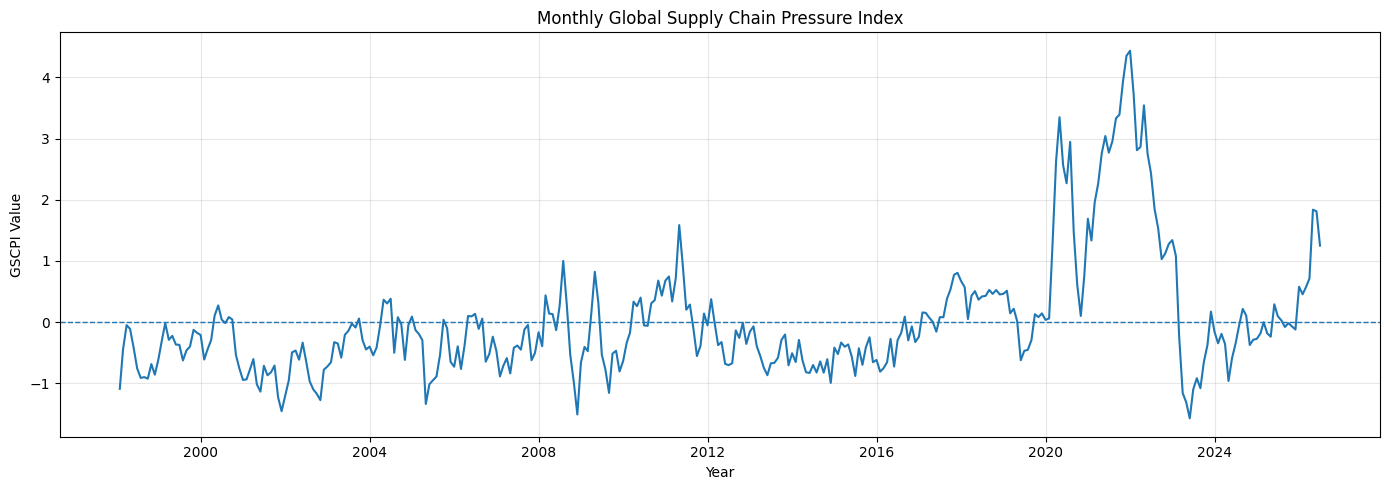

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    gscpi_df["Date"],
    gscpi_df["GSCPI"]
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Monthly Global Supply Chain Pressure Index")
plt.xlabel("Year")
plt.ylabel("GSCPI Value")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Figure 1. Monthly Global Supply Chain Pressure Index.**  
The chart shows monthly changes in global supply chain pressure from January 1998 through June 2026.

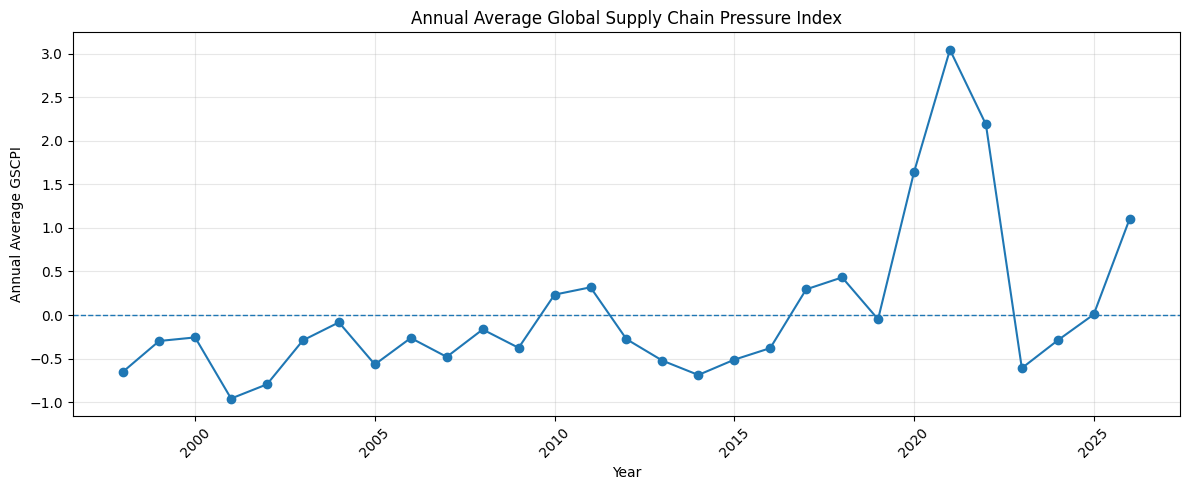

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    annual_gscpi["Year"],
    annual_gscpi["Annual_GSCPI"],
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Annual Average Global Supply Chain Pressure Index")
plt.xlabel("Year")
plt.ylabel("Annual Average GSCPI")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Figure 2. Annual Average Global Supply Chain Pressure Index.**  
The chart shows the annual averages created from the monthly GSCPI values. The 2026 value represents only January through June and is not part of the DataCo correlation period.

In [ ]:
merged_gscpi_delivery = pd.merge(
    annual_late_delivery,
    annual_gscpi,
    on="Year",
    how="inner"
)

merged_gscpi_delivery

,Year,Annual_Late_Delivery_Rate,Annual_GSCPI
0,2015,0.548635,-0.512525
1,2016,0.550695,-0.379732
2,2017,0.544477,0.294784
3,2018,0.562883,0.432057


The annual GSCPI series contains 29 records from 1998 through 2026. The 2026 average is based only on data from January through June, while the correlation analysis uses the overlapping DataCo years from 2015 through 2018.

In [ ]:
delivery_gscpi_correlation = merged_gscpi_delivery[
    ["Annual_Late_Delivery_Rate", "Annual_GSCPI"]
].corr().iloc[0, 1]

print(
    "Correlation between annual GSCPI and annual late-delivery rate:",
    round(delivery_gscpi_correlation, 4)
)

Correlation between annual GSCPI and annual late-delivery rate: 0.4136


In [ ]:
# Monthly-resolution correlation (primary test — far more data points than annual)
from scipy import stats

# Monthly late-delivery rate from DataCo
dataco_df["Month"] = dataco_df["Order_Date"].dt.to_period("M")
late_month = dataco_df.groupby("Month")["Late_delivery_risk"].mean()

# Monthly GSCPI (already have Month period on gscpi_df)
gscpi_month = gscpi_df.groupby("Month")["GSCPI"].mean()

monthly = pd.concat(
    [late_month.rename("Late_Rate"), gscpi_month.rename("GSCPI")],
    axis=1
).dropna()

r_month, p_month = stats.pearsonr(monthly["Late_Rate"], monthly["GSCPI"])

print("MONTHLY (primary):")
print(f"  Correlation coefficient  r = {r_month:+.3f}  (p = {p_month:.3f}, n = {len(monthly)})")
print(f"  Late-rate range across months: {monthly['Late_Rate'].min():.3f} - {monthly['Late_Rate'].max():.3f}")
print()
print("ANNUAL (secondary, only 4 points):")
print(f"  Correlation coefficient  r = {delivery_gscpi_correlation:+.3f}  (n = {len(merged_gscpi_delivery)})")

MONTHLY (primary):
  Correlation coefficient  r = -0.059  (p = 0.728, n = 37)
  Late-rate range across months: 0.519 - 0.568

ANNUAL (secondary, only 4 points):
  Correlation coefficient  r = +0.414  (n = 4)


In [ ]:
print("Overlapping years:", merged_gscpi_delivery["Year"].tolist())
print("Number of overlapping years:", len(merged_gscpi_delivery))

Overlapping years: [2015, 2016, 2017, 2018]
Number of overlapping years: 4


### Assumption Verification

**Assumption:** GSCPI is measurably correlated with operational late-delivery risk.

**Result: the available data does not show a measurable relationship.** At the monthly level, using 37 aligned observations from January 2015 through January 2018, the correlation between GSCPI and the DataCo late-delivery rate was **r = -0.059**, which is close to zero and indicates essentially no linear relationship.

The annual correlation was higher at **r = 0.414**, but it was based on only four yearly observations. In addition, 2018 represents a partial year with approximately 2,123 orders. Therefore, the annual result is not considered reliable, especially because its direction changes when the data is analyzed at the more detailed monthly level. The monthly late-delivery rate also remained within a narrow range of 51.9% to 56.8%, showing little variation across changes in GSCPI. Therefore, the assumption is not supported for the operational-risk layer, and GSCPI should be treated as an optional feature unless a dataset with greater temporal variation provides stronger evidence.

### Financial-Layer Limitation

The Taiwanese Bankruptcy dataset does not contain a company-level date or year field. Therefore, the bankruptcy records could not be aggregated into annual rates or matched reliably with the GSCPI series. A financial-risk correlation was not calculated because assigning artificial years to the records would not produce a valid result.

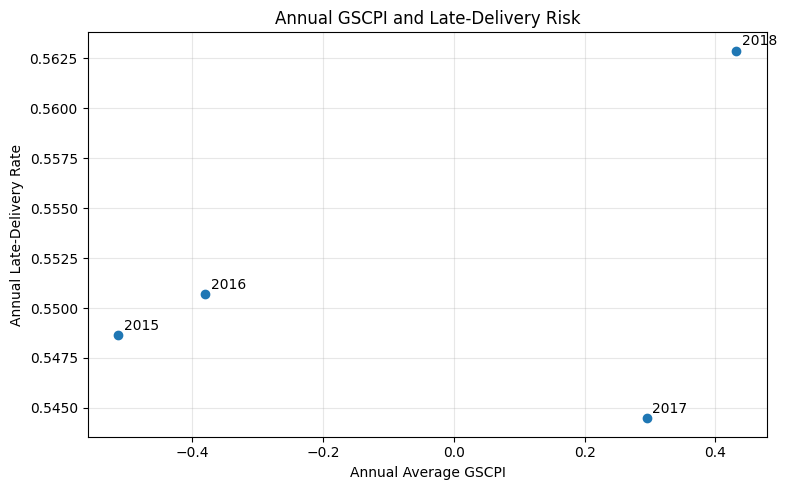

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    merged_gscpi_delivery["Annual_GSCPI"],
    merged_gscpi_delivery["Annual_Late_Delivery_Rate"]
)

for _, row in merged_gscpi_delivery.iterrows():
    plt.annotate(
        int(row["Year"]),
        (
            row["Annual_GSCPI"],
            row["Annual_Late_Delivery_Rate"]
        ),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("Annual GSCPI and Late-Delivery Risk")
plt.xlabel("Annual Average GSCPI")
plt.ylabel("Annual Late-Delivery Rate")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Figure 3. Annual Relationship Between GSCPI and Late-Delivery Risk.**  
The annual analysis shows a positive correlation of **r = 0.41**, but this result is based on only four yearly observations and should not be considered reliable. When the relationship was tested using 37 monthly observations, the correlation decreased to **r = -0.06**, indicating essentially no linear relationship between GSCPI and late-delivery risk.

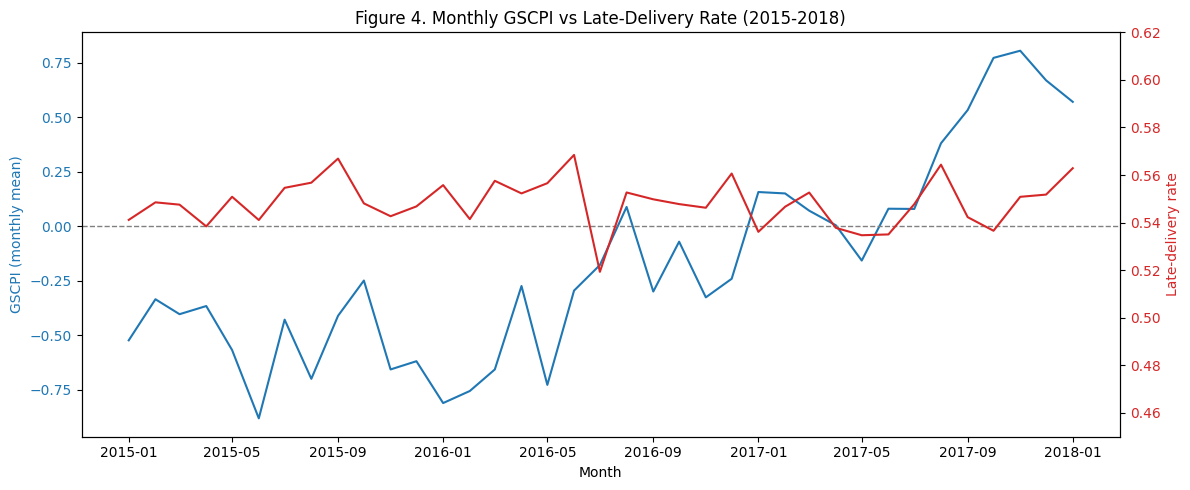

In [ ]:
# Figure 4: GSCPI vs late-delivery rate over time (monthly, 2015-2018)
fig, ax1 = plt.subplots(figsize=(12, 5))

mth = monthly.copy()
mth.index = mth.index.to_timestamp()

ax1.plot(mth.index, mth["GSCPI"], color="tab:blue", label="GSCPI")
ax1.set_xlabel("Month")
ax1.set_ylabel("GSCPI (monthly mean)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.axhline(0, linestyle="--", linewidth=1, color="gray")

ax2 = ax1.twinx()
ax2.plot(mth.index, mth["Late_Rate"], color="tab:red", label="Late-delivery rate")
ax2.set_ylabel("Late-delivery rate", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")
ax2.set_ylim(0.45, 0.62)

plt.title("Figure 4. Monthly GSCPI vs Late-Delivery Rate (2015-2018)")
fig.tight_layout()
plt.show()


**Figure 4. Monthly GSCPI vs Late-Delivery Rate (2015-2018).**  
GSCPI (blue) swings widely while the late-delivery rate (red) stays almost flat in a ~52-57% band. The visual confirms the near-zero monthly correlation: movement in macro pressure is not tracked by movement in the delivery-risk label.

### GSCPI Split Methodology

The GSCPI dataset was not divided into training and test sets because it was used as a time-series enrichment source for aggregation and correlation analysis rather than as a supervised classification dataset.